# 00.07 — Watch the Q-table learn from episode 0 → 300

<div><span style="display:inline-block;background:#8B5CF6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPISODE</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span><span style="display:inline-block;background:#E45756;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ALPHA</span><span style="display:inline-block;background:#00A6A6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">GAMMA</span><span style="display:inline-block;background:#FF6B9A;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPSILON</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

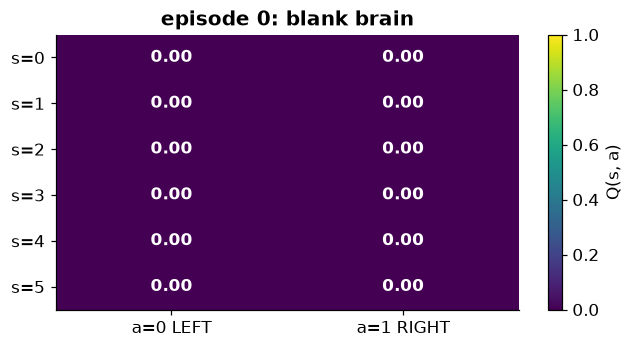

In [2]:
def train(alpha=.2,gamma=.95,epsilon=.25,episodes=300,seed=7):
    rng=np.random.default_rng(seed); env=LineWorld(); Q=np.zeros((6,2)); snaps={0:Q.copy()}; returns=[]; wanted={1,2,5,10,25,50,100,200,300}
    for ep in range(1,episodes+1):
        obs,_=env.reset(); total=0
        while True:
            action=int(rng.integers(0,2)) if rng.random()<epsilon else int(np.argmax(Q[obs]))
            n,r,term,trunc,_=env.step(action); future=0 if term else np.max(Q[n]); target=r+gamma*future; Q[obs,action]+=alpha*(target-Q[obs,action]); total+=r; obs=n
            if term or trunc: break
        returns.append(total)
        if ep in wanted: snaps[ep]=Q.copy()
    return Q,snaps,returns
Q,snaps,returns=train(); fig=q_heatmap(snaps[0],"episode 0: blank brain"); plt.show()

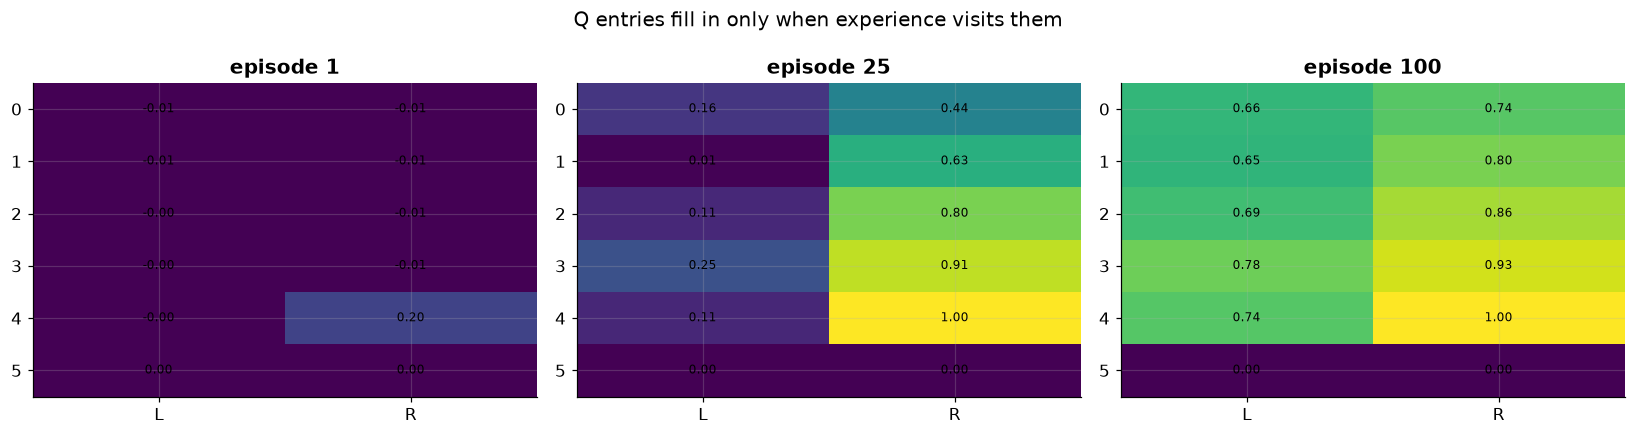

In [3]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,ep in zip(axes,[1,25,100]):
    ax.imshow(snaps[ep],aspect="auto",cmap="viridis",vmin=0,vmax=1); ax.set_title(f"episode {ep}"); ax.set_xticks([0,1],["L","R"]); ax.set_yticks(range(6))
    for i in range(6):
        for j in range(2): ax.text(j,i,f"{snaps[ep][i,j]:.2f}",ha="center",va="center",fontsize=8)
plt.suptitle("Q entries fill in only when experience visits them"); plt.tight_layout(); plt.show()

A Q entry changes only when its **state-action pair is visited**. Value then propagates backward because earlier updates bootstrap from learned next-state values.

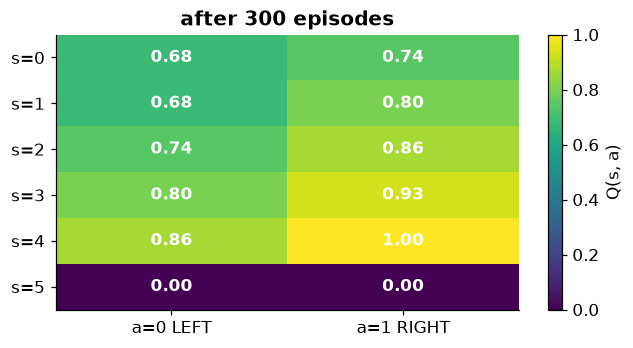

In [4]:
fig=q_heatmap(snaps[300],"after 300 episodes"); plt.show()

RIGHT converges near `.740, .800, .864, .930, 1.000` because of the Bellman calculations from notebook 00.03 — not because 300 has magical significance.

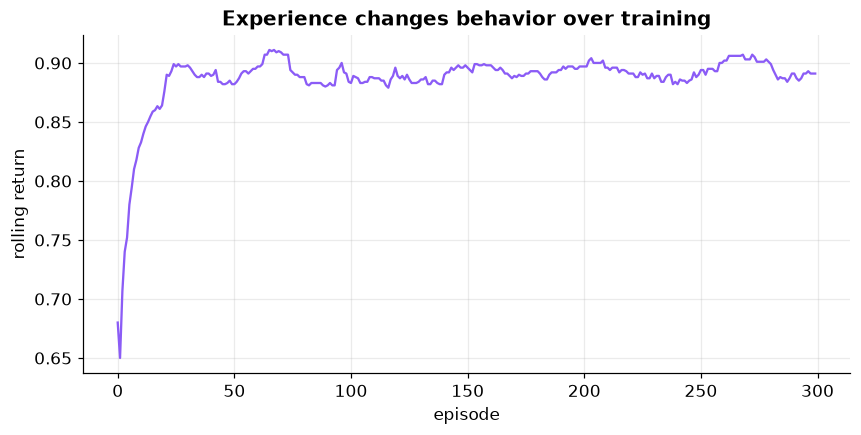

In [5]:
plt.figure(figsize=(9,4)); plt.plot(pd.Series(returns).rolling(20,min_periods=1).mean(),color=COLORS["EPISODE"]); plt.xlabel("episode"); plt.ylabel("rolling return"); plt.title("Experience changes behavior over training"); plt.show()

A **greedy policy** after training simply means choose `argmax_a Q(s,a)` with no epsilon exploration.

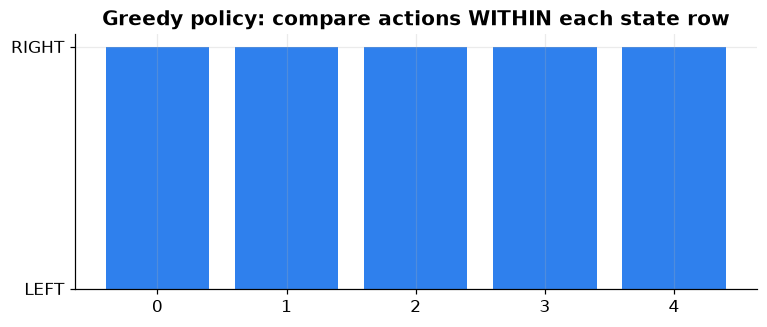

In [6]:
policy=np.argmax(Q[:5],axis=1); plt.figure(figsize=(8,3)); plt.bar(range(5),policy,color=COLORS["EXPLOIT"]); plt.yticks([0,1],["LEFT","RIGHT"]); plt.xticks(range(5)); plt.title("Greedy policy: compare actions WITHIN each state row"); plt.show()

There is no general rule `Q(s) > Q(s′)`. The action choice compares `Q(s,LEFT)` versus `Q(s,RIGHT)` for the **same** current state.